In [200]:
import numpy as np

import pandas as pd
import matplotlib.pyplot as plt

# connect google colab
from google.colab import drive
drive.mount('/content/drive')

"""
used to import the datset easily ..
#from tensorflow.keras.datasets import fashion_mnist

#(x_train,y_train) , (x_test,y_test) = fashion_mnist.load_data()
"""

data = pd.read_csv('/content/drive/MyDrive/fashion-mnist_train.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [201]:
data.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [202]:
data = np.array(data)
m,n = data.shape
np.random.shuffle(data) # to get the randomise the values not in the order


In [203]:
print(m,n)

60000 785


In [204]:
#  SPLITING A DATA

train_data = data[0:int(0.8*m),:]  # split the dataset 80/20
test_data = data[int(0.8*m):m , :] # 80% train , 20% for test

x_train = train_data[: , 1:].T  # Training features (transpose for model input)
y_train = train_data[: , 0]     # Training labels

x_test = test_data[: , 1:].T   # Testing features
y_test = test_data[:,0]        # Testing labels

x_train = x_train/255.0      # Normalize pixel values to range 0–1
x_test = x_test/255.0       # Normalize pixel values to range 0–1

print(x_train.shape , y_train.shape)
print(x_test.shape , y_test.shape)

(784, 48000) (48000,)
(784, 12000) (12000,)


In [205]:
# intialize params

def init_parameter():

  w1 = np.random.rand(10 , 784)-0.5
  b1 = np.random.rand(10,1) - 0.5
  w2 = np.random.rand(10,10) -0.5
  b2 = np.random.rand(10,1) - 0.5

  return w1,b1,w2,b2


"""

Initializes weights and biases for a 2-layer neural network.

w1, b1 -> Parameters for the first layer (784 inputs → 10 neurons)
w2, b2 -> Parameters for the second layer (10 neurons → 10 outputs)

Random values are initialized between -0.5 and 0.5
to prevent neurons from starting with identical parameters.
"""

In [206]:
# FORWARD PROPAGATION


def relu(x):
  return np.maximum(x,0)


def softmax(z):
  return np.exp(z) / sum(np.exp(z))


def forwardProp(w1,b1,w2,b2,x):

  Z1 = w1.dot(x) + b1
  A1 = relu(Z1)

  Z2 = w2.dot(A1) + b2
  A2 = softmax(Z2)

  return Z1 , A1 , Z2 ,A2

  """


Forward propagation passes the input through the neural network.

Z1 → A1 : First layer + ReLU activation
Z2 → A2 : Output layer + Softmax activation

A2 contains the predicted probabilities for the 10 classes.
"""



In [207]:
# BACKWARD PROPAGATION

def one_hot(y):
  one_hot_y = np.zeros((y.size , y.max()+1))
  one_hot_y[np.arange(y.size),y] = 1

  return one_hot_y.T




def backwardProp(w1,b1,w2,b2,z1,a1,z2,a2,x,y):

  one_hot_y = one_hot(y)

   # Output layer: prediction error

  dZ2 = a2 - one_hot_y
   # Gradients for second layer

  dW2 = 1/m * dZ2.dot(a1.T)
  dB2 = 1/m * np.sum(dZ2)

  # Propagate error back through ReLU and second layer
  dZ1 = w2.T.dot(dZ2) * (z1 >0)
   # Gradients for first layer
  dW1 = 1/m * dZ1.dot(x.T)
  dB1 = 1/m * np.sum(dZ1)

  return dW1 , dB1 , dW2 ,dB2


"""
Backward propagation calculates how much each weight and bias
contributed to the prediction error.

one_hot() → Converts labels into one-hot encoded vectors.

dZ2 → Output error = prediction - actual
dW2, dB2 → Gradients for the second layer

dZ1 → Sends the error backward through W2 and ReLU.
dW1, dB1 → Gradients for the first layer.

These gradients are later used by gradient descent to update
the weights and biases and reduce the prediction error.
"""


In [208]:
# UPDATE WEIGHTS


def get_prediction(a2):
  return np.argmax(a2,0)


def get_accuracy(pred , y):
  return np.sum(pred == y)/y.size


def update_weights(w1,b1,w2,b2,dw1 , db1 , dw2 , db2 , learning_rate):

  w1 = w1 - learning_rate * dw1
  b1 = b1 - learning_rate * db1
  w2 = w2 - learning_rate * dw2
  b2 = b2 - learning_rate * db2

  return w1,b1,w2,b2

In [209]:
# GRADIENT DESCENT

def gradient_descent(x,y, learning_rate , epochs):

  w1,b1,w2,b2 = init_parameter()


  for i in range(epochs):
    z1 , a1,z2,a2 = forwardProp(w1,b1,w2,b2,x)

    dw1 , db1 , dw2,db2 = backwardProp(w1,b1,w2,b2,z1,a1,z2,a2,x,y)

    w1,b1,w2,b2 = update_weights(w1,b1,w2,b2,dw1,db1,dw2,db2,learning_rate)


    if (i%20==0):
      print("Iteration Number : ", i)
      print("Accuracy : ", get_accuracy(get_prediction(a2),y))


  return w1,b1,w2,b2



In [211]:
w1,b1,w2,b2 = gradient_descent(x_train,y_train,0.1,1000)


Iteration Number :  0
Accuracy :  0.10027083333333334
Iteration Number :  20
Accuracy :  0.22935416666666666
Iteration Number :  40
Accuracy :  0.39995833333333336
Iteration Number :  60
Accuracy :  0.5147708333333333
Iteration Number :  80
Accuracy :  0.5541666666666667
Iteration Number :  100
Accuracy :  0.5798333333333333
Iteration Number :  120
Accuracy :  0.599375
Iteration Number :  140
Accuracy :  0.6145625
Iteration Number :  160
Accuracy :  0.6274375
Iteration Number :  180
Accuracy :  0.6386666666666667
Iteration Number :  200
Accuracy :  0.6474166666666666
Iteration Number :  220
Accuracy :  0.6430208333333334
Iteration Number :  240
Accuracy :  0.6521875
Iteration Number :  260
Accuracy :  0.6589791666666667
Iteration Number :  280
Accuracy :  0.6658958333333334
Iteration Number :  300
Accuracy :  0.6715625
Iteration Number :  320
Accuracy :  0.6767291666666667
Iteration Number :  340
Accuracy :  0.6815625
Iteration Number :  360
Accuracy :  0.686125
Iteration Number :  380

Predicted value ;  [0]
Actual Value :  0


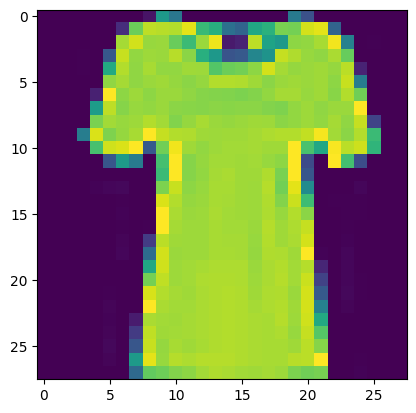

In [218]:
# get the prediction

val_ind = 727

z1_val, a1_val , z2_val ,a2_val = forwardProp(w1,b1,w2,b2,x_test[: ,val_ind,None])

print("Predicted value ; ", get_prediction(a2_val))
print("Actual Value : ", y_test[val_ind])


img_array = x_test[: , val_ind , None]
img_array = img_array.reshape((28,28))
plt.imshow(img_array)
plt.show()


In [213]:
# TO get Accuracy

z1_val, a1_val , z2_val ,a2_val = forwardProp(w1,b1,w2,b2,x_test)
val_acc = get_accuracy(get_prediction(a2_val), y_test)
print("Validation accuracy = ", val_acc)



Validation accuracy =  0.76175
